# **Laboratorio N°10: Redes neuronales con Keras**

**Curso:** Aprendizaje Estadistico 2026-2  
**Estudiante:** Jeronimo Lopez Gomez

------



| Función de activación | Ventajas | Desventajas |
| --------------------- | -------- | ----------- |
| Lineal | Simple y rápida de calcular | Le falta introducir no linealidad, no limita el rango de salida |
| Sigmoide | Mapea la salida al rango (0, 1), útil para clasificación binaria | Se satura fácilmente, tiene gradientes pequeños, no tiene media cero |
| Tangente hiperbólica | Mapea la salida al rango (-1, 1), tiene media cero, es más fuerte que la sigmoide | Se satura fácilmente, tiene gradientes pequeños |
| ReLU | Introduce no linealidad, tiene gradientes grandes, es rápida de calcular | Puede morir si la entrada es negativa, no tiene media cero |


### Keras: https://keras.io/api/layers/activations/

Keras es una bilbioteca con librerias de código abierto para entrenar modelos de deep learning DL que puede ejecutarse en TensorFlow. Keras permite construir bloque de arquitectura de la redes neuronales, y permite construir desde un perceptron hasta redes neuronales convolucionales  y recurrentes de una manera amigable con el usuario.


---
---
# Laboratorio

**1.)** Para el dataset make a moon de sklearn, construir un modelo de una red neuronal con keras para clasificar los datos.

**2.)** Para el dataset load digits, construir un modelo de red neuronal empleando keras para realizar la clasificación.

## 1. Clasificación con `make_moons`

El conjunto `make_moons` contiene dos clases distribuidas en forma de medias lunas. Utilizaremos una red neuronal con 2 capas ocultas **ReLU** y una salida **sigmoid** para la clasificación binaria.

### 1.1. Preparación de los datos

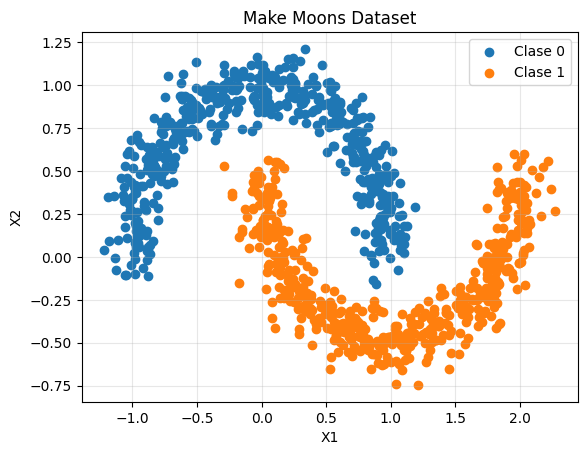

In [38]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

#Queremos resultados que puedan ser reproducibles
SEED = 42
keras.utils.set_random_seed(SEED)

#Cargamos y graficamos el dataset de make_moons
X_moons, y_moons = make_moons(n_samples=1000, noise=0.1, random_state=42)

plt.scatter(X_moons[y_moons == 0, 0], X_moons[y_moons == 0, 1], label='Clase 0')
plt.scatter(X_moons[y_moons == 1, 0], X_moons[y_moons == 1, 1], label='Clase 1')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Make Moons Dataset')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=SEED
)

### 1.2. Definición del Modelo y Entrenamiento

Retomamos la arquitectura del ejemplo realizado en clase con `make_circles`: 2 entradas - 4 neuronas - 8 neuronas - 1 salida. Usamos `binary_crossentropy` como función de pérdida y `sigmoid` como función de activación en la capa de salida y finalmente entrenamos el modelo durante 200 épocas.

In [39]:
#Definimos la función para construir el modelo de red neuronal para el dataset de make_moons

def build_model_moons():
    """
    Construye un modelo de red neuronal para el dataset de make_moons.
    """
    model = keras.models.Sequential()
    model.add(keras.layers.Dense(4, input_dim=2, activation='relu'))
    model.add(keras.layers.Dense(8, activation='relu'))
    model.add(keras.layers.Dense(1, activation='sigmoid'))

    opt = keras.optimizers.SGD(learning_rate=0.01)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

keras.backend.clear_session()
model_moons = build_model_moons()
model_moons.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61 (244.00 B)

 Trainable params: 61 (244.00 B)

 Non-trainable params: 0 (0.00 B)

In [40]:
#Realizamos el entrenamiento del modelo con los datos de entrenamiento y validación,
#y evaluamos su desempeño en los conjuntos de entrenamiento y prueba.
history_moons = model_moons.fit(
    X_train_m, y_train_m,
    validation_data=(X_test_m, y_test_m),
    epochs=200, verbose=1
)

_, train_acc_m = model_moons.evaluate(X_train_m, y_train_m, verbose=0)
_, test_acc_m = model_moons.evaluate(X_test_m, y_test_m, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc_m, test_acc_m))

Epoch 1/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.4800 - loss: 0.6741 - val_accuracy: 0.4500 - val_loss: 0.6585
Epoch 2/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4888 - loss: 0.6433 - val_accuracy: 0.5600 - val_loss: 0.6318
Epoch 3/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7100 - loss: 0.6161 - val_accuracy: 0.8150 - val_loss: 0.6072
Epoch 4/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8213 - loss: 0.5913 - val_accuracy: 0.8150 - val_loss: 0.5843
Epoch 5/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8225 - loss: 0.5681 - val_accuracy: 0.8150 - val_loss: 0.5631
Epoch 6/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8238 - loss: 0.5463 - val_accuracy: 0.8050 - val_loss: 0.5431
Epoch 7/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8225 - loss: 0.5258 - val_accuracy: 0.8050 - val_loss: 0.5243
Epoch 8/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8225 - loss: 0.5068 - val_accuracy: 0.8050 -

### 1.3. Resultados de Entrenamiento 

Comparamos la pérdida (`loss`) y la precisión (`accuracy`) en los datos de entrenamiento y de prueba. Una diferencia grande entre ambas curvas puede indicar que el modelo no generaliza bien.

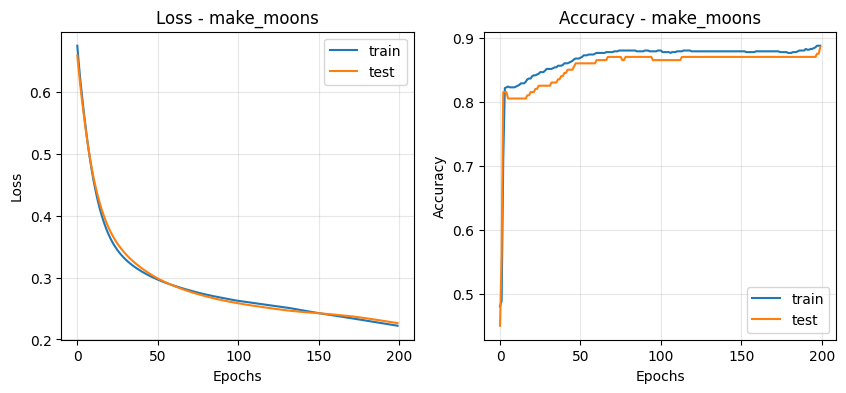

In [41]:
plt.figure(figsize=(10, 4))

plt.subplot(121)
plt.title('Loss - make_moons')
plt.plot(history_moons.history['loss'], label='train')
plt.plot(history_moons.history['val_loss'], label='test')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(122)
plt.title('Accuracy - make_moons')
plt.plot(history_moons.history['accuracy'], label='train')
plt.plot(history_moons.history['val_accuracy'], label='test')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:
#Predicción del modelo

y_prob_m = model_moons.predict(X_test_m)

# Convertir probabilidades en clases (0 o 1)
y_pred_m = (y_prob_m >= 0.5).astype(int).ravel()

# Comparar las predicciones con los valores reales
for i in range(10):
    print(f'Real: {y_test_m[i]} | Predicción: {y_pred_m[i]} | Probabilidad: {y_prob_m[i,0]:.3f}')

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
Real: 1 | Predicción: 1 | Probabilidad: 0.983
Real: 0 | Predicción: 0 | Probabilidad: 0.183
Real: 1 | Predicción: 1 | Probabilidad: 0.996
Real: 0 | Predicción: 0 | Probabilidad: 0.100
Real: 1 | Predicción: 1 | Probabilidad: 0.991
Real: 1 | Predicción: 1 | Probabilidad: 0.979
Real: 0 | Predicción: 1 | Probabilidad: 0.574
Real: 0 | Predicción: 1 | Probabilidad: 0.785
Real: 1 | Predicción: 1 | Probabilidad: 0.999
Real: 0 | Predicción: 0 | Probabilidad: 0.240


## 2. Clasificación con `load_digits`

El conjunto ya cargado contiene imágenes de **8 × 8 píxeles**, representadas mediante **64 características**. Se seleccionaron los dígitos del **0 al 5** (`n_class=6`), de modo que la salida de la red tendrá seis neuronas.

A diferencia del ejercicio anterior, utilizaremos **softmax** para obtener una probabilidad por clase y `sparse_categorical_crossentropy` porque las etiquetas son números enteros (0, 1, …, 5).

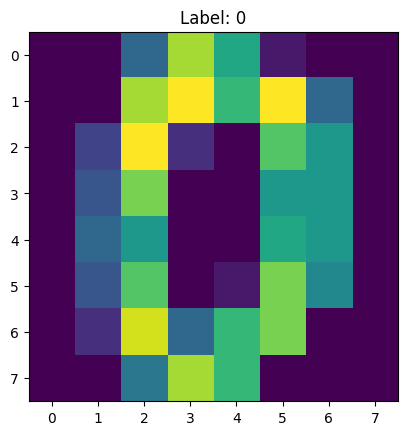

In [43]:
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score

#Cargamos el dataset de dígitos y limitamos a las clases 0 a 5 para simplificar el problema
digits = load_digits(n_class=6)
X, y = digits.data, digits.target
n_samples, n_features = X.shape

plt.imshow(X[0].reshape(8, 8))
plt.title(f'Label: {y[0]}')
plt.show()

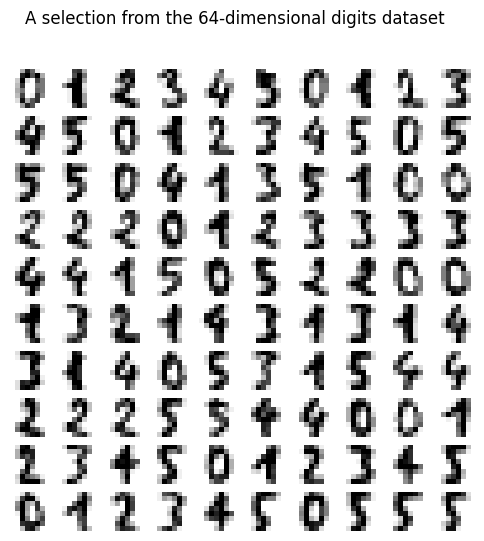

In [44]:
#Graficamos una selección de imágenes del dataset de dígitos

fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(6, 6))
for idx, ax in enumerate(axs.ravel()):
    ax.imshow(X[idx].reshape((8, 8)), cmap=plt.cm.binary)
    ax.axis("off")
_ = fig.suptitle("A selection from the 64-dimensional digits dataset")

#Realizamos la división de los datos en conjuntos de entrenamiento y prueba.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

### 2.1. Preparación de los datos

Los valores de intensidad de los píxeles van de 0 a 16; los dividimos por 16 para llevarlos al intervalo de 0 a 1.

In [45]:
print('Forma de X:', X.shape)
print('Clases:', np.unique(y))

#Normalizamos los datos dividiendo entre 16.0, ya que los valores de los píxeles están en el rango [0, 16].
X_train = X_train / 16.0
X_test = X_test / 16.0

Forma de X: (1083, 64)
Clases: [0 1 2 3 4 5]


### 2.2. Modelo y entrenamiento

Construimos una red con 64 entradas, dos capas ocultas Dense (32 y 16 neuronas) y 6 salidas. Procedemos de manera similar al caso anterior. En este caso usamos funciones de activación `relu` para las capas ocultas y una activación `softmax` en la capa de salida.

In [46]:
#Definición de la función para construir el modelo de red neuronal para el dataset de dígitos

def build_model_digits():
    """
    Construye un modelo de red neuronal para el dataset de dígitos.
    """
    model = keras.models.Sequential()
    model.add(keras.layers.Dense(32, input_dim=64, activation='relu'))
    model.add(keras.layers.Dense(16, activation='relu'))
    model.add(keras.layers.Dense(6, activation='softmax'))

    opt = keras.optimizers.SGD(learning_rate=0.01)
    model.compile(loss='sparse_categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

#Borramos la sesión de Keras para liberar recursos y evitar conflictos con modelos anteriores.
keras.backend.clear_session()

model_digits = build_model_digits()
model_digits.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,710 (10.59 KB)

 Trainable params: 2,710 (10.59 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
#Realizamos el entrenamiento del modelo con los datos de entrenamiento y validación.
history_digits = model_digits.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=500, verbose=1
)

_, train_acc_d = model_digits.evaluate(X_train, y_train, verbose=0)
_, test_acc_d = model_digits.evaluate(X_test, y_test, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc_d, test_acc_d))

Epoch 1/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2079 - loss: 1.7879 - val_accuracy: 0.2258 - val_loss: 1.7517
Epoch 2/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2460 - loss: 1.7473 - val_accuracy: 0.2903 - val_loss: 1.7121
Epoch 3/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3279 - loss: 1.7149 - val_accuracy: 0.3963 - val_loss: 1.6759
Epoch 4/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3995 - loss: 1.6818 - val_accuracy: 0.4654 - val_loss: 1.6347
Epoch 5/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4342 - loss: 1.6431 - val_accuracy: 0.4839 - val_loss: 1.5895
Epoch 6/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4607 - loss: 1.6030 - val_accuracy: 0.5300 - val_loss: 1.5455
Epoch 7/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4965 - loss: 1.5603 - val_accuracy: 0.5668 - val_loss: 1.4987
Epoch 8/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5277 - loss: 1.5123 - val_accuracy: 0.5899 - 

### 2.3. Evaluación de los resultados

Graficamos la evolución de la pérdida y la precisión para comparar el comportamiento en entrenamiento y prueba.

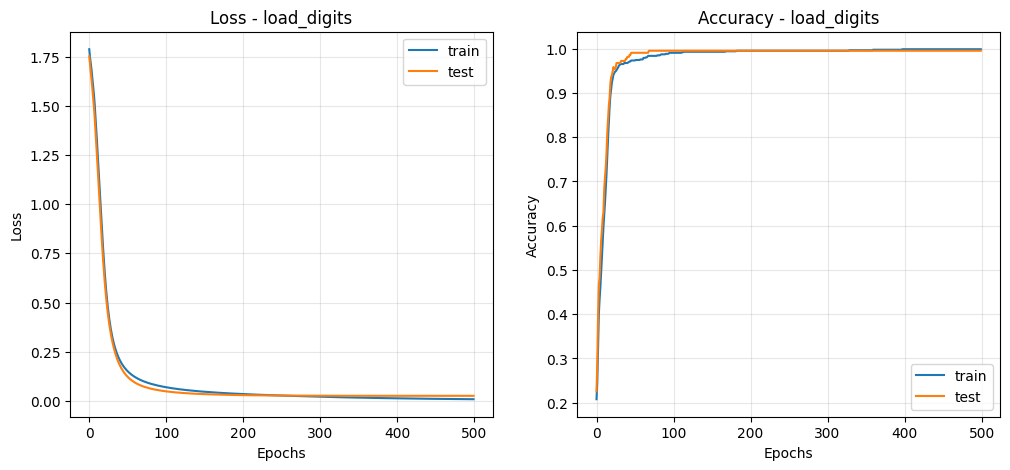

In [48]:
plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.title('Loss - load_digits')
plt.plot(history_digits.history['loss'], label='train')
plt.plot(history_digits.history['val_loss'], label='test')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(122)
plt.title('Accuracy - load_digits')
plt.plot(history_digits.history['accuracy'], label='train')
plt.plot(history_digits.history['val_accuracy'], label='test')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 2.4. Predicciones del modelo

La última capa entrega seis probabilidades por imagen. Con `argmax` elegimos la clase con mayor probabilidad y la comparamos con la etiqueta real.

In [49]:
y_prob = model_digits.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

for i in range(10):
    print(f'Real: {y_test[i]} - Predicción: {y_pred[i]} | Probabilidad: {y_prob[i, y_pred[i]]:.3f}')

Real: 1 - Predicción: 1 | Probabilidad: 0.998
Real: 3 - Predicción: 3 | Probabilidad: 1.000
Real: 2 - Predicción: 2 | Probabilidad: 1.000
Real: 1 - Predicción: 1 | Probabilidad: 0.991
Real: 3 - Predicción: 3 | Probabilidad: 0.996
Real: 4 - Predicción: 4 | Probabilidad: 1.000
Real: 3 - Predicción: 3 | Probabilidad: 1.000
Real: 2 - Predicción: 2 | Probabilidad: 0.998
Real: 2 - Predicción: 2 | Probabilidad: 1.000
Real: 0 - Predicción: 0 | Probabilidad: 1.000
